In [1]:
# =============================================================================
# CS-781 Phase 1 — Architecture #4: Gated Dilated Convolutional LM
# with Causal Global Context Fusion
#
# Inspired by (cited, not imported):
#   - Gated Convolutional Networks for Language Modeling (Dauphin et al., 2017)
#     — GLU-gated causal convolutions, no attention/recurrence
#   - WaveNet-style dilated causal convolutions (van den Oord et al., 2016)
#     — exponentially growing receptive field via dilation doubling per layer
#
# OUR OWN MODIFICATION: each block also computes a causal CUMULATIVE-MEAN
# "global context" summary (fully parallel via cumsum — no recurrence, no
# attention, no per-step loop) and fuses it with the local convolution's GLU
# output via a learned per-position sigmoid gate. Rationale: dilated
# convolutions alone build long-range context only gradually across layers;
# a cheap always-available running summary gives every position direct
# access to "everything said so far in the case" (useful for legal text,
# where an early-stated fact/party name needs to stay available throughout
# a long document), while the gate lets the model decide per-position how
# much to rely on that global summary vs. the local syntactic window.
#
# NO SELF-ATTENTION ANYWHERE — fundamentally different mechanism from
# Arch #1 (causal self-attention + RoPE), Arch #2 (local-window + persistent
# memory attention), and Arch #3 (cross-attention encoder-decoder). Also the
# cheapest of the four: pure Conv1d + cumsum, no O(T^2) attention, no Python
# loops over time/heads.
#
# Run in Kaggle: paste each "# %%" block as its own cell, in order.
# =============================================================================

# %% [1] Imports & HF login
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

import json, math, random, time, zipfile
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from kaggle_secrets import UserSecretsClient
from huggingface_hub import login, hf_hub_download

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("HF")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"
TEST_FILE = "Phase_1_Pretraining/Test/test.json"

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Device: cuda


In [2]:
# %% [2] Config
SEED = 42
random.seed(SEED); torch.manual_seed(SEED)

# !!! EDIT THIS to the dataset slug Kaggle gave your committed Arch #1 notebook's output.
ARTIFACT_PATH = "/kaggle/input/datasets/akashmalgav2/dataset4"

BLOCK_SIZE = 1024          # same as Arch #1/#2 for comparability
N_LAYER = 16               # conv blocks are cheaper per-layer than attention, so more layers
N_EMBD = 640
KERNEL_SIZE = 3
MAX_DILATION = 64          # dilation doubles per layer: 1,2,4,...,64,1,2,4,... (cycles)
FFN_MULT = 4
DROPOUT = 0.1

BATCH_SIZE = 8
GRAD_ACCUM = 4             # effective batch = 32
LR = 3e-4
MIN_LR = 3e-5
WARMUP_STEPS = 300
MAX_STEPS = 6000           # same budget as Arch #1/#3 — this architecture should be fast
EVAL_EVERY = 500
LOG_EVERY = 50

TARGET_GEN_WORDS = 128
MAX_GEN_TOKENS = 384
TEMPERATURE = 0.7
TOP_P = 0.95
NO_REPEAT_NGRAM = 3

OUTPUT_DIR = "/kaggle/working/cs781_phase1_arch4"
os.makedirs(OUTPUT_DIR, exist_ok=True)
CKPT_PATH = os.path.join(OUTPUT_DIR, "model.pt")
PREDICTION_PATH = os.path.join(OUTPUT_DIR, "prediction.json")
SUBMISSION_ZIP = os.path.join(OUTPUT_DIR, "submission_phase1_arch4.zip")
LOSS_PLOT_PATH = os.path.join(OUTPUT_DIR, "loss.png")

In [3]:
# %% [3] Load the REUSED tokenizer (same as Arch #1/#2/#3 — no retraining)
with open(f"{ARTIFACT_PATH}/legal_bpe.json", "r", encoding="utf-8") as f:
    _tok = json.load(f)
vocab = _tok["itos"]
merges = [tuple(p) for p in _tok["merges"]]
token_to_id = {tok: i for i, tok in enumerate(vocab)}
merges_rank = {p: i for i, p in enumerate(merges)}
PAD_ID = token_to_id["<pad>"]
UNK_ID = token_to_id["<unk>"]
BOS_ID = token_to_id["<s>"]
EOS_ID = token_to_id["</s>"]
ACTUAL_VOCAB_SIZE = len(vocab)
EOW = "\u0100"

def word_to_symbols(word):
    return tuple(chr(b) for b in word.encode("utf-8", "ignore")) + (EOW,)

def bpe_encode_word(word):
    symbols = list(word_to_symbols(word))
    while len(symbols) > 1:
        pairs = [(symbols[i], symbols[i + 1]) for i in range(len(symbols) - 1)]
        ranked = [(merges_rank[p], p) for p in pairs if p in merges_rank]
        if not ranked:
            break
        _, best = min(ranked)
        new_symbols, i = [], 0
        while i < len(symbols):
            if i < len(symbols) - 1 and symbols[i] == best[0] and symbols[i + 1] == best[1]:
                new_symbols.append(best[0] + best[1]); i += 2
            else:
                new_symbols.append(symbols[i]); i += 1
        symbols = new_symbols
    return symbols

def encode(text, add_bos=True, add_eos=True):
    ids = [BOS_ID] if add_bos else []
    for w in text.split():
        for sym in bpe_encode_word(w):
            ids.append(token_to_id.get(sym, UNK_ID))
    if add_eos:
        ids.append(EOS_ID)
    return ids

def decode(ids):
    byte_buf = []
    for i in ids:
        if i in (PAD_ID, BOS_ID, EOS_ID, UNK_ID):
            continue
        tok = vocab[i]
        for ch in tok:
            if ch == EOW:
                byte_buf.append(0x20)
            elif ord(ch) <= 255:
                byte_buf.append(ord(ch))
    return bytes(byte_buf).decode("utf-8", errors="replace").strip()

print("Loaded tokenizer. Vocab size:", ACTUAL_VOCAB_SIZE)
print("Sanity check:", decode(encode("The petitioner filed the present appeal.")))

train_tokens = torch.load(f"{ARTIFACT_PATH}/train_tokens.pt").tolist()
val_tokens = torch.load(f"{ARTIFACT_PATH}/val_tokens.pt").tolist()
print(f"Loaded pre-tokenized corpus: train={len(train_tokens):,} val={len(val_tokens):,}")

Loaded tokenizer. Vocab size: 32000
Sanity check: The petitioner filed the present appeal.
Loaded pre-tokenized corpus: train=60,000,000 val=1,066,512


Train blocks: torch.Size([58593, 1024]) Val blocks: torch.Size([1041, 1024])
Model size: 106.56M parameters
step     0 | loss 10.5162 | lr 0.00e+00 | elapsed 0.1m
step    50 | loss 8.7061 | lr 5.00e-05 | elapsed 2.2m
step   100 | loss 7.0397 | lr 1.00e-04 | elapsed 4.4m
step   150 | loss 6.7261 | lr 1.50e-04 | elapsed 6.5m
step   200 | loss 6.1993 | lr 2.00e-04 | elapsed 8.7m
step   250 | loss 5.7569 | lr 2.50e-04 | elapsed 10.8m
step   300 | loss 5.6255 | lr 3.00e-04 | elapsed 13.0m
step   350 | loss 5.1279 | lr 3.00e-04 | elapsed 15.1m
step   400 | loss 5.2905 | lr 3.00e-04 | elapsed 17.3m
step   450 | loss 5.1819 | lr 3.00e-04 | elapsed 19.5m
step   500 | loss 4.8886 | lr 2.99e-04 | elapsed 21.6m
  [eval] step 500 | val_loss 4.4171 | perplexity 82.86
step   550 | loss 4.4407 | lr 2.99e-04 | elapsed 24.0m
step   600 | loss 4.6407 | lr 2.98e-04 | elapsed 26.1m
step   650 | loss 4.6449 | lr 2.97e-04 | elapsed 28.3m
step   700 | loss 4.1839 | lr 2.97e-04 | elapsed 30.4m
step   750 | los

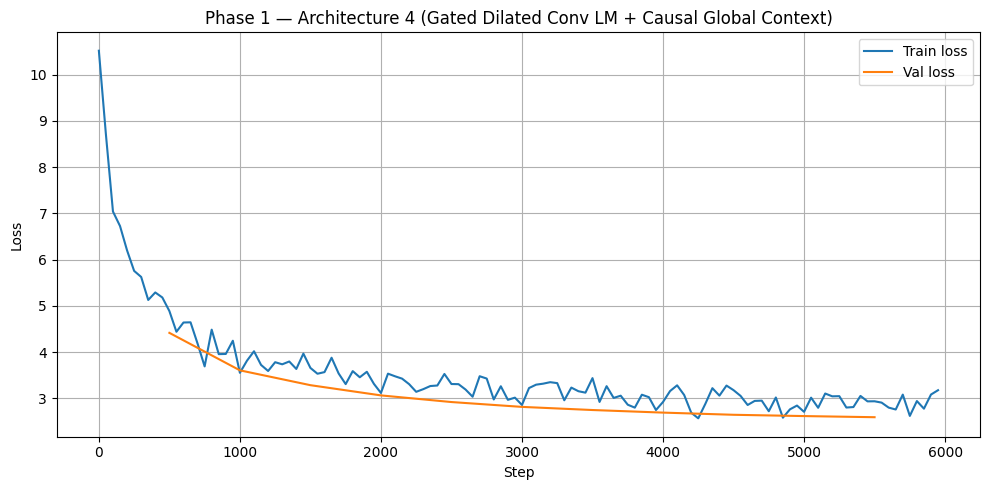

Saved checkpoint: /kaggle/working/cs781_phase1_arch4/model.pt


test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test examples: 1000
Generated 50/1000
Generated 100/1000
Generated 150/1000
Generated 200/1000
Generated 250/1000
Generated 300/1000
Generated 350/1000
Generated 400/1000
Generated 450/1000
Generated 500/1000
Generated 550/1000
Generated 600/1000
Generated 650/1000
Generated 700/1000
Generated 750/1000
Generated 800/1000
Generated 850/1000
Generated 900/1000
Generated 950/1000
Generated 1000/1000
Codabench submission ready: /kaggle/working/cs781_phase1_arch4/submission_phase1_arch4.zip


In [4]:






# %% [4] Chunk into blocks (plain causal LM, same style as Arch #1/#2)
def make_blocks(tokens, block_size):
    n = (len(tokens) // block_size) * block_size
    tokens = tokens[:n]
    return torch.tensor(tokens, dtype=torch.long).view(-1, block_size)

train_blocks = make_blocks(train_tokens, BLOCK_SIZE)
val_blocks = make_blocks(val_tokens, BLOCK_SIZE)
print("Train blocks:", train_blocks.shape, "Val blocks:", val_blocks.shape)

class BlockDataset(Dataset):
    def __init__(self, blocks):
        self.blocks = blocks
    def __len__(self):
        return self.blocks.size(0)
    def __getitem__(self, idx):
        x = self.blocks[idx][:-1]
        y = self.blocks[idx][1:]
        return x, y

train_ds = BlockDataset(train_blocks)
val_ds = BlockDataset(val_blocks)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True,
                           num_workers=2, pin_memory=True, persistent_workers=True)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, drop_last=True,
                         num_workers=2, pin_memory=True, persistent_workers=True)

# %% [5] Model: Gated Dilated Convolutional LM with Causal Global Context Fusion
class CausalDilatedConv(nn.Module):
    """Depthwise causal dilated 1D convolution — left-padded so position t
    never sees position > t (preserves autoregressive validity)."""
    def __init__(self, channels, kernel_size, dilation):
        super().__init__()
        self.left_pad = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(channels, channels, kernel_size,
                               dilation=dilation, groups=channels, padding=0)

    def forward(self, x):  # x: (B, C, T)
        x = F.pad(x, (self.left_pad, 0))
        return self.conv(x)

class GatedConvBlock(nn.Module):
    def __init__(self, n_embd, kernel_size, dilation, dropout):
        super().__init__()
        self.ln = nn.LayerNorm(n_embd)
        self.in_proj = nn.Conv1d(n_embd, 2 * n_embd, 1)     # pointwise expand for GLU
        self.dconv = CausalDilatedConv(2 * n_embd, kernel_size, dilation)
        self.global_proj = nn.Linear(n_embd, n_embd)         # projects the cumulative-mean summary
        self.gate_proj = nn.Linear(n_embd, n_embd)            # OUR CONTRIBUTION: local/global fusion gate
        self.out_proj = nn.Conv1d(n_embd, n_embd, 1)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):  # x: (B, T, C)
        residual = x
        h = self.ln(x)
        h_t = h.transpose(1, 2)              # (B, C, T)
        h_t = self.in_proj(h_t)              # (B, 2C, T)
        h_t = self.dconv(h_t)                # causal dilated conv, still (B, 2C, T)
        a, b = h_t.chunk(2, dim=1)
        local = a * torch.sigmoid(b)         # GLU gating -> (B, C, T)
        local = local.transpose(1, 2)        # (B, T, C)

        # Causal global context: cumulative mean up to each position.
        # Fully parallel (cumsum), no recurrence loop, no numerical instability.
        cumsum = torch.cumsum(local, dim=1)
        counts = torch.arange(1, local.size(1) + 1, device=local.device, dtype=local.dtype).view(1, -1, 1)
        global_ctx = self.global_proj(cumsum / counts)

        gate = torch.sigmoid(self.gate_proj(h))     # per-position, per-channel fusion gate
        fused = gate * local + (1 - gate) * global_ctx
        fused = self.drop(fused)

        out = self.out_proj(fused.transpose(1, 2)).transpose(1, 2)
        return residual + out

class MLP(nn.Module):
    def __init__(self, n_embd, mult, dropout):
        super().__init__()
        self.ln = nn.LayerNorm(n_embd)
        self.fc1 = nn.Linear(n_embd, mult * n_embd)
        self.fc2 = nn.Linear(mult * n_embd, n_embd)
        self.drop = nn.Dropout(dropout)
    def forward(self, x):
        h = self.ln(x)
        return x + self.drop(self.fc2(F.gelu(self.fc1(h))))

class Block(nn.Module):
    def __init__(self, n_embd, kernel_size, dilation, ffn_mult, dropout):
        super().__init__()
        self.conv_block = GatedConvBlock(n_embd, kernel_size, dilation, dropout)
        self.mlp = MLP(n_embd, ffn_mult, dropout)
    def forward(self, x):
        x = self.conv_block(x)
        x = self.mlp(x)
        return x

class GatedConvLM(nn.Module):
    def __init__(self, vocab_size, n_layer, n_embd, block_size, kernel_size, max_dilation, ffn_mult, dropout):
        super().__init__()
        self.block_size = block_size
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.drop = nn.Dropout(dropout)

        dilations = []
        d = 1
        for _ in range(n_layer):
            dilations.append(d)
            d = d * 2 if d < max_dilation else 1   # cycle 1,2,4,...,max_dilation,1,2,...

        self.blocks = nn.ModuleList([
            Block(n_embd, kernel_size, dilations[i], ffn_mult, dropout) for i in range(n_layer)
        ])
        self.ln_f = nn.LayerNorm(n_embd)
        self.head = nn.Linear(n_embd, vocab_size, bias=False)
        self.tok_emb.weight = self.head.weight
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, (nn.Linear, nn.Conv1d)):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)
            if getattr(module, "bias", None) is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(T, device=idx.device).unsqueeze(0)
        x = self.drop(self.tok_emb(idx) + self.pos_emb(pos))
        for blk in self.blocks:
            x = blk(x)
        x = self.ln_f(x)
        logits = self.head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=0.7, top_p=0.95, eos_id=None, no_repeat_ngram=3):
        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.block_size:]
            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / max(temperature, 1e-5)

            if no_repeat_ngram > 0 and idx.size(1) >= no_repeat_ngram:
                for b in range(idx.size(0)):
                    seq = idx[b].tolist()
                    ngram = tuple(seq[-(no_repeat_ngram - 1):])
                    banned = set()
                    for i in range(len(seq) - no_repeat_ngram + 1):
                        if tuple(seq[i:i + no_repeat_ngram - 1]) == ngram:
                            banned.add(seq[i + no_repeat_ngram - 1])
                    for t in banned:
                        logits[b, t] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            sorted_probs, sorted_idx = torch.sort(probs, descending=True, dim=-1)
            cum_probs = torch.cumsum(sorted_probs, dim=-1)
            cutoff = (cum_probs > top_p)
            cutoff[:, 1:] = cutoff[:, :-1].clone()
            cutoff[:, 0] = False
            sorted_probs[cutoff] = 0.0
            sorted_probs = sorted_probs / sorted_probs.sum(dim=-1, keepdim=True)
            next_sorted = torch.multinomial(sorted_probs, num_samples=1)
            next_id = sorted_idx.gather(-1, next_sorted)
            idx = torch.cat([idx, next_id], dim=1)
            if eos_id is not None and (next_id == eos_id).all():
                break
        return idx

model = GatedConvLM(ACTUAL_VOCAB_SIZE, N_LAYER, N_EMBD, BLOCK_SIZE, KERNEL_SIZE, MAX_DILATION, FFN_MULT, DROPOUT).to(device)
n_params = sum(p.numel() for p in model.parameters())
print(f"Model size: {n_params/1e6:.2f}M parameters")
assert 50e6 <= n_params <= 300e6, "Model must be 50M-300M params — adjust N_LAYER/N_EMBD"

# %% [6] Training loop
optimizer = torch.optim.AdamW(model.parameters(), lr=LR, betas=(0.9, 0.95), weight_decay=0.1)
scaler = torch.amp.GradScaler("cuda", enabled=torch.cuda.is_available())

def lr_at(step):
    if step < WARMUP_STEPS:
        return LR * step / max(1, WARMUP_STEPS)
    progress = (step - WARMUP_STEPS) / max(1, MAX_STEPS - WARMUP_STEPS)
    progress = min(progress, 1.0)
    return MIN_LR + 0.5 * (LR - MIN_LR) * (1 + math.cos(math.pi * progress))

@torch.no_grad()
def evaluate():
    model.eval()
    losses = []
    for i, (x, y) in enumerate(val_loader):
        if i >= 50:
            break
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(x, y)
        losses.append(loss.item())
    model.train()
    return sum(losses) / max(1, len(losses))

history = {"step": [], "train_loss": [], "eval_step": [], "eval_loss": []}
step = 0
t0 = time.time()
model.train()
data_iter = iter(train_loader)

while step < MAX_STEPS:
    optimizer.zero_grad(set_to_none=True)
    accum_loss = 0.0
    for _ in range(GRAD_ACCUM):
        try:
            x, y = next(data_iter)
        except StopIteration:
            data_iter = iter(train_loader)
            x, y = next(data_iter)
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            _, loss = model(x, y)
            loss = loss / GRAD_ACCUM
        scaler.scale(loss).backward()
        accum_loss += loss.item()

    lr = lr_at(step)
    for g in optimizer.param_groups:
        g["lr"] = lr
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    scaler.step(optimizer)
    scaler.update()

    if step % LOG_EVERY == 0:
        elapsed = time.time() - t0
        print(f"step {step:5d} | loss {accum_loss:.4f} | lr {lr:.2e} | elapsed {elapsed/60:.1f}m")
        history["step"].append(step)
        history["train_loss"].append(accum_loss)

    if step % EVAL_EVERY == 0 and step > 0:
        val_loss = evaluate()
        ppl = math.exp(val_loss)
        print(f"  [eval] step {step} | val_loss {val_loss:.4f} | perplexity {ppl:.2f}")
        history["eval_step"].append(step)
        history["eval_loss"].append(val_loss)

    step += 1

final_val_loss = evaluate()
final_ppl = math.exp(final_val_loss)
print(f"FINAL val loss: {final_val_loss:.4f} | perplexity: {final_ppl:.4f}")

# %% [7] Plot loss curve
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.plot(history["step"], history["train_loss"], label="Train loss")
plt.plot(history["eval_step"], history["eval_loss"], label="Val loss")
plt.xlabel("Step"); plt.ylabel("Loss")
plt.title("Phase 1 — Architecture 4 (Gated Dilated Conv LM + Causal Global Context)")
plt.legend(); plt.grid(True); plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

# %% [8] Save checkpoint
torch.save({
    "model_state_dict": model.state_dict(),
    "config": dict(vocab_size=ACTUAL_VOCAB_SIZE, n_layer=N_LAYER, n_embd=N_EMBD,
                   block_size=BLOCK_SIZE, kernel_size=KERNEL_SIZE, max_dilation=MAX_DILATION,
                   ffn_mult=FFN_MULT, dropout=DROPOUT),
}, CKPT_PATH)
print("Saved checkpoint:", CKPT_PATH)

# %% [9] Generate 128-word continuations for the official test prompts
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO, filename=TEST_FILE, repo_type="dataset", token=HF_TOKEN
)
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)
print("Test examples:", len(test_data))

model.eval()
predictions = {}
MAX_PROMPT_TOKENS = BLOCK_SIZE - MAX_GEN_TOKENS

for i, (example_id, record) in enumerate(test_data.items()):
    prompt_ids = encode(record["text"], add_bos=True, add_eos=False)[:MAX_PROMPT_TOKENS]
    idx = torch.tensor([prompt_ids], dtype=torch.long, device=device)
    out = model.generate(idx, max_new_tokens=MAX_GEN_TOKENS,
                          temperature=TEMPERATURE, top_p=TOP_P, eos_id=EOS_ID,
                          no_repeat_ngram=NO_REPEAT_NGRAM)
    gen_ids = out[0, len(prompt_ids):].tolist()
    gen_text = decode(gen_ids)
    gen_words = gen_text.split()[:TARGET_GEN_WORDS]
    predictions[str(example_id)] = {"text": " ".join(gen_words)}
    if (i + 1) % 50 == 0:
        print(f"Generated {i+1}/{len(test_data)}")

# %% [10] Save prediction.json + zip for Codabench
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(predictions, f, ensure_ascii=False, indent=2)
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    zf.write(PREDICTION_PATH, arcname="prediction.json")
print("Codabench submission ready:", SUBMISSION_ZIP)